# LL efficiency versus ΔR from drOnlyEff.py

A simple notebook for **one-dimensional LL and denominator histograms**. There are no heatmaps, pT/vxy projections, or extra categories.

**Before histogram production:** the inspected `drOnlyEff.py` creates `genvtx_pt_vxy_dr_LL` but fills `genvtx_dr_LL`. Make those names agree on LPC before producing the output. The clearest correction is `h.make("genvtx_dr_LL", "dr_LL")`. This notebook does not change that configuration.

Set `f_sig` below to your actual LPC output. The default filename `drOnlyEff.coffea` is a suggested name, not a verified file. Run with the LPC kernel. Keep the sample selection from the earlier notebooks.

Unlike the previous 3D histograms, these histograms do **not impose the old pT 0–100 GeV and vxy 0–20 cm bin limits**. Their event population follows the input and upstream cuts, so the efficiencies need not equal those from the 3D projections.


In [1]:
from pathlib import Path
import gc
import re
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from hist.intervals import ratio_uncertainty

LPC_REPO = Path('/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe')
# Replace this default if your output has another filename.
f_sig = LPC_REPO / 'python_analysis/coffea/VertexRes2026/drOnlyEff.coffea'
cut = 'cut0'

samples = {10: {0.2: [100]}, 20: {0.2: [100]}, 30: {0.2: [100]}, 40: {0.2: [100]}, 50: {0.2: [100]}, 60: {0.1: [100], 0.2: [100]}, 70: {0.1: [100], 0.2: [100]}, 80: {0.1: [100], 0.2: [100]}, 90: {0.1: [100], 0.2: [100]}, 100: {0.2: [100]}}

print('Input:', f_sig)
print('Cut:', cut)


Input: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/drOnlyEff.coffea
Cut: cut0


In [2]:
loaded = util.load(str(f_sig))
sig_histo = loaded[0]

# Prefer the consistent name. Also accept the old long name if its fill
# was corrected and the resulting histogram really has only a ΔR axis.
if 'genvtx_dr_LL' in sig_histo:
    numerator_name = 'genvtx_dr_LL'

else:
    raise KeyError('No LL histogram found. Check the make/fill name mismatch in drOnlyEff.py.')

histograms = {
    'LL': sig_histo[numerator_name],
    'den': sig_histo['genvtx_dr_den'],
}
del sig_histo, loaded
gc.collect()
print('Numerator:', numerator_name)
print('Denominator: genvtx_dr_den')


Numerator: genvtx_dr_LL
Denominator: genvtx_dr_den


In [3]:
# Select signal points using the same filename convention as plotTools.signalPoint.
# No plotting helper is needed.
available_samples = list(histograms['den'].axes['samp'])
parsed_samples = []
for name in available_samples:
    match = re.search(r'Mchi-(\d+p\d+)_dMchi-(\d+p\d+)_ctau-(\d+)', name)
    if match is None:
        continue
    mchi = float(match.group(1).replace('p', '.'))
    dmchi = float(match.group(2).replace('p', '.'))
    lifetime = float(match.group(3))
    mass1 = mchi - dmchi / 2
    parsed_samples.append((name, mass1, dmchi / mass1, lifetime))

selected_names = []
for m1, deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            matches = [
                name for name, mass1, splitting, lifetime in parsed_samples
                if np.isclose(mass1, m1, rtol=1e-8, atol=1e-8)
                and np.isclose(splitting, delta, rtol=1e-8, atol=1e-8)
                and lifetime == ctau
            ]
            if len(matches) != 1:
                raise ValueError(f'Expected one sample for {(m1, delta, ctau)}, found {matches}')
            if matches[0] in selected_names:
                raise ValueError(f'Duplicate sample: {matches[0]}')
            selected_names.append(matches[0])
if not selected_names:
    raise ValueError('No signal points selected.')
print('Selected samples:')
for name in selected_names:
    print(' ', name)


# Both histograms must have one numerical axis after selecting sample/cut.
dr_edges = np.asarray(histograms['den'].axes['dr_den'].edges).copy()
num_counts = np.zeros(len(dr_edges) - 1, dtype=float)
den_counts = np.zeros_like(num_counts)

for suffix, total in [('LL', num_counts), ('den', den_counts)]:
    for name in selected_names:
        h = histograms[suffix][{'samp': name, 'cut': cut}]
        if len(h.axes) != 1 or h.axes[0].name != f'dr_{suffix}':
            raise ValueError(f'{suffix} must have only one numerical axis, dr_{suffix}.')
        np.testing.assert_array_equal(dr_edges, h.axes[0].edges)
        total += h.values(flow=False)

print('ΔR edges:', dr_edges)
print('Only regular ΔR bins are included; underflow/overflow are excluded.')
del histograms, h
gc.collect()


Selected samples:
  sig_2022_Mchi-11p0_dMchi-2p0_ctau-100
  sig_2022_Mchi-22p0_dMchi-4p0_ctau-100
  sig_2022_Mchi-33p0_dMchi-6p0_ctau-100
  sig_2022_Mchi-44p0_dMchi-8p0_ctau-100
  sig_2022_Mchi-55p0_dMchi-10p0_ctau-100
  sig_2022_Mchi-63p0_dMchi-6p0_ctau-100
  sig_2022_Mchi-66p0_dMchi-12p0_ctau-100
  sig_2022_Mchi-73p5_dMchi-7p0_ctau-100
  sig_2022_Mchi-77p0_dMchi-14p0_ctau-100
  sig_2022_Mchi-84p0_dMchi-8p0_ctau-100
  sig_2022_Mchi-88p0_dMchi-16p0_ctau-100
  sig_2022_Mchi-94p5_dMchi-9p0_ctau-100
  sig_2022_Mchi-99p0_dMchi-18p0_ctau-100
  sig_2022_Mchi-110p0_dMchi-20p0_ctau-100
ΔR edges: [0.   0.01 0.02 0.04 0.06 0.08 0.1  0.15 0.2  0.3  0.4  0.5  0.7  1.
 1.5  2.   3.   4.   5.  ]
Only regular ΔR bins are included; underflow/overflow are excluded.


0

In [4]:
# Same efficiency and uncertainty method as the previous notebooks.
for label, counts in [('numerator', num_counts), ('denominator', den_counts)]:
    if not np.all(np.isfinite(counts)) or np.any(counts < 0):
        raise ValueError(f'Invalid {label} counts.')
    if not np.allclose(counts, np.round(counts)):
        raise ValueError('Binomial uncertainties assume unit-weight event counts.')
if np.any(num_counts > den_counts):
    raise ValueError('LL counts exceed the denominator.')

valid = den_counts > 0
efficiency = np.divide(num_counts, den_counts,
                       out=np.full_like(num_counts, np.nan), where=valid)
uncertainty = np.full((2, len(den_counts)), np.nan)
if np.any(valid):
    uncertainty[:, valid] = ratio_uncertainty(
        num_counts[valid], den_counts[valid], 'efficiency'
    )

for i, (low, high) in enumerate(zip(dr_edges[:-1], dr_edges[1:])):
    if valid[i]:
        print(f'[{low:g}, {high:g}): {num_counts[i]:g} / {den_counts[i]:g} '
              f'= {100 * efficiency[i]:.3f}% '
              f'(-{100 * uncertainty[0,i]:.3f}, +{100 * uncertainty[1,i]:.3f} percentage points)')
    else:
        print(f'[{low:g}, {high:g}): denominator 0; omitted')


[0, 0.01): 154 / 4852 = 3.174% (-0.252, +0.272 percentage points)
[0.01, 0.02): 699 / 14415 = 4.849% (-0.179, +0.186 percentage points)
[0.02, 0.04): 3512 / 57540 = 6.104% (-0.100, +0.101 percentage points)
[0.04, 0.06): 6046 / 91927 = 6.577% (-0.082, +0.083 percentage points)
[0.06, 0.08): 7854 / 121347 = 6.472% (-0.071, +0.071 percentage points)
[0.08, 0.1): 9822 / 145792 = 6.737% (-0.066, +0.066 percentage points)
[0.1, 0.15): 29777 / 443029 = 6.721% (-0.038, +0.038 percentage points)
[0.15, 0.2): 34980 / 518481 = 6.747% (-0.035, +0.035 percentage points)
[0.2, 0.3): 72075 / 1.1522e+06 = 6.255% (-0.023, +0.023 percentage points)
[0.3, 0.4): 48551 / 1.20091e+06 = 4.043% (-0.018, +0.018 percentage points)
[0.4, 0.5): 39817 / 1.17452e+06 = 3.390% (-0.017, +0.017 percentage points)
[0.5, 0.7): 61641 / 2.14064e+06 = 2.880% (-0.011, +0.011 percentage points)
[0.7, 1): 57254 / 2.55762e+06 = 2.239% (-0.009, +0.009 percentage points)
[1, 1.5): 45420 / 2.88682e+06 = 1.573% (-0.007, +0.007 per

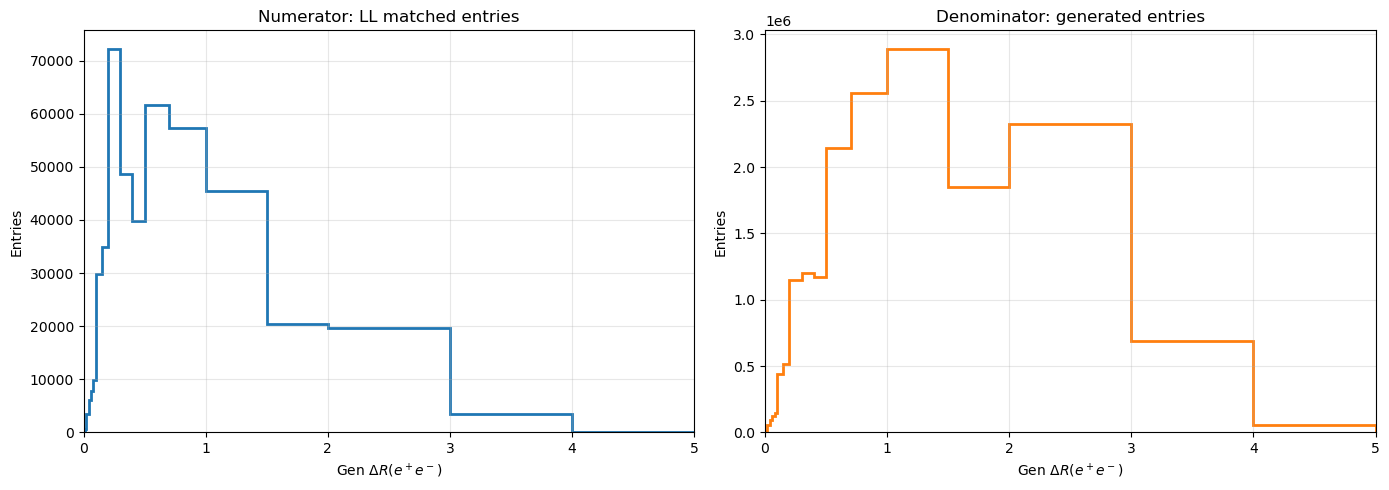

In [6]:
fig_counts, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].stairs(
    num_counts,
    dr_edges,
    color="tab:blue",
    linewidth=2,
)
axes[0].set_title("Numerator: LL matched entries")
axes[0].set_ylabel("Entries")

axes[1].stairs(
    den_counts,
    dr_edges,
    color="tab:orange",
    linewidth=2,
)
axes[1].set_title("Denominator: generated entries")
axes[1].set_ylabel("Entries")

for axis in axes:
    axis.set_xlabel(r"Gen $\Delta R(e^+e^-)$")
    axis.set_xlim(dr_edges[0], dr_edges[-1])
    axis.set_ylim(bottom=0)
    axis.grid(alpha=0.3)

fig_counts.tight_layout()
plt.show()

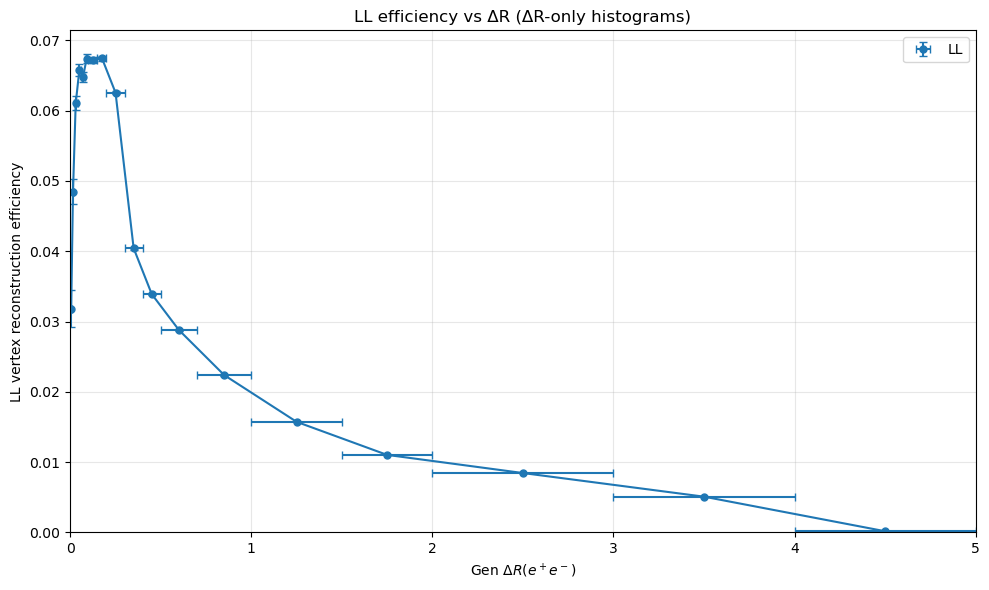

In [5]:
x = (dr_edges[:-1] + dr_edges[1:]) / 2
xerr = np.vstack((x - dr_edges[:-1], dr_edges[1:] - x))
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, efficiency, color='tab:blue', linewidth=1.5)
ax.errorbar(x[valid], efficiency[valid],
            xerr=xerr[:, valid], yerr=uncertainty[:, valid],
            fmt='o', color='tab:blue', markersize=5, capsize=3, label='LL')
ax.set_xlim(dr_edges[0], dr_edges[-1])
# For a closer look at small ΔR, use ax.set_xlim(0, 0.2).
ax.set_ylim(bottom=0)
ax.set_xlabel(r'Gen $\Delta R(e^+e^-)$')
ax.set_ylabel('LL vertex reconstruction efficiency')
ax.set_title('LL efficiency vs ΔR (ΔR-only histograms)')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
